# Module 7 — Pretrained Models and the Hugging Face Ecosystem

## Lesson 7.4 — Loading and Using Pretrained Models


So far we have mostly used pretrained models through `pipeline`, a single call that hides everything between text going in and a label coming out. That is the right tool for trying a model quickly. But as soon as you build something real, you need to see inside: to control how long inputs are cut, to process thousands of texts efficiently, to read the raw scores rather than just a label, to run on the right device, and to save a model so your application doesn't depend on a download.

This note opens up the pipeline. We take the sentiment model from Notes 7.1 to 7.3 and do every step ourselves: load the tokeniser and model explicitly, prepare inputs with padding, truncation and attention masks, run the model correctly for inference, turn its raw outputs into probabilities and labels, batch inputs efficiently, and save and reload the result. At each step we check our version against the pipeline's, so you know the explicit code does exactly the same job.

**Key question:** *What happens between loading a model by name and getting a trustworthy prediction, and how do we control each step?*

### Learning objectives
- use the pipeline API with explicit devices, batching and truncation;
- load a tokeniser and model explicitly, and reproduce a pipeline's outputs with them;
- explain padding, truncation and attention masks, and show what goes wrong without a mask;
- turn logits into probabilities and labels by hand;
- run inference correctly: eval mode, `inference_mode`, and devices;
- batch inputs efficiently, estimate memory use, and save and reload a model and its tokeniser.

### Prerequisites

 read Notes 7.1–7.3. You'll need the tokeniser ideas from Note 7.2 (WordPiece, special tokens, a model and its tokeniser as a pair), softmax and cross-entropy from Module 2, dropout from Module 3, and attention masks from Note 6.3.

### Setup

The usual imports, seeds and device check, and the same harmless warnings as before (TqdmWarning, the unauthenticated-request message and, on a Mac, a few `W…` lines). One more message will appear in Section 4, "Token indices sequence length is longer than the specified maximum…", which we trigger on purpose.

**Environment and reference results.** Use Python 3.12 and [requirements.txt](../static/notebook-support/module78/requirements.txt) (also supplied at the root of the Module 7/8 notebook bundle). Install packages into a separate environment, restart the kernel, and run from the beginning. The saved outputs are the author's CPU reference run, with approved explanatory corrections. Seeds and artifact revisions reduce variation; numbers and timings can differ across hardware. No account or paid API is required for the public teaching models. Initial model/data downloads require internet access.

In [1]:
import os, time, shutil, hashlib
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

# Freeze the public artifacts used by the recorded experiments.
MODEL_REVISIONS = {'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'distilbert/distilbert-base-uncased-finetuned-sst-2-english': '714eb0fa89d2f80546fda750413ed43d93601a13', 'sentence-transformers/all-MiniLM-L6-v2': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41', 'HuggingFaceTB/SmolLM2-135M': '93efa2f097d58c2a74874c7e644dbc9b0cee75a2', 'distilbert/distilgpt2': '2290a62682d06624634c1f46a6ad5be0f47f38aa', 'HuggingFaceTB/SmolLM2-135M-Instruct': '12fd25f77366fa6b3b4b768ec3050bf629380bac', 'HuggingFaceTB/SmolLM2-360M-Instruct': 'a10cc1512eabd3dde888204e902eca88bddb4951', 'Qwen/Qwen2.5-0.5B': '060db6499f32faf8b98477b0a26969ef7d8b9987', 'Qwen/Qwen2.5-7B': 'd149729398750b98c0af14eb82c78cfe92750796', 'google-bert/bert-large-uncased': '6da4b6a26a1877e173fca3225479512db81a5e5b', 'distilbert/distilbert-base-uncased': '12040accade4e8a0f71eabdb258fecc2e7e948be', 'google-bert/bert-base-uncased': '86b5e0934494bd15c9632b12f734a8a67f723594', 'cardiffnlp/twitter-roberta-base-sentiment-latest': '3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7', 'distilbert/distilbert-base-cased-distilled-squad': '564e9b582944a57a3e586bbb98fd6f0a4118db7f', 'google/vit-base-patch16-224': '3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3', 'sshleifer/distilbart-cnn-12-6': 'a4f8f3ea906ed274767e9906dbaede7531d660ff', 'textattack/distilbert-base-uncased-imdb': '5b0f46c2fc4b86bf21f0ec0409bed77ee142b332', 'google/gemma-2-2b': 'c5ebcd40d208330abc697524c919956e692655cf', 'meta-llama/Llama-3.2-1B': '4e20de362430cd3b72f300e6b0f18e50e7166e08'}
DATASET_REVISIONS = {'stanfordnlp/imdb': 'e6281661ce1c48d982bc483cf8a173c1bbeb5d31', 'stanfordnlp/sst2': '8d51e7e4887a4caaa95b3fbebbf53c0490b58bbb'}

def benchmark_clock():
    """Read elapsed time after completing any queued CUDA work."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    import time
    return time.perf_counter()

def ordered_fingerprint(texts, labels):
    """Hash ordered text/label pairs so paired predictions cannot be silently misaligned."""
    import json, hashlib
    rows = [[str(t), int(y)] for t, y in zip(texts, labels)]
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(',', ':')).encode()).hexdigest()

/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1017 13:24:46.556000 76340 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1017 13:24:46.640000 76340 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1017 13:24:46.660000 76340 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


PyTorch 2.14.1 | device: cpu


## 1. The Big Picture: From Repository to Working Code

Every use of a pretrained text model follows the same five steps, whether a pipeline does them for you or you write them yourself:

1. **Load** the tokeniser and the model from the same repository (Note 7.2).
2. **Preprocess:** turn texts into token IDs, cut long ones to a maximum length, pad short ones so a batch forms a rectangle, and build an attention mask that marks which positions are real.
3. **Run** the model in inference mode, on the right device.
4. **Decode** the outputs: raw scores (logits) → probabilities → labels.
5. **Save** the model and tokeniser if your application needs its own copy.

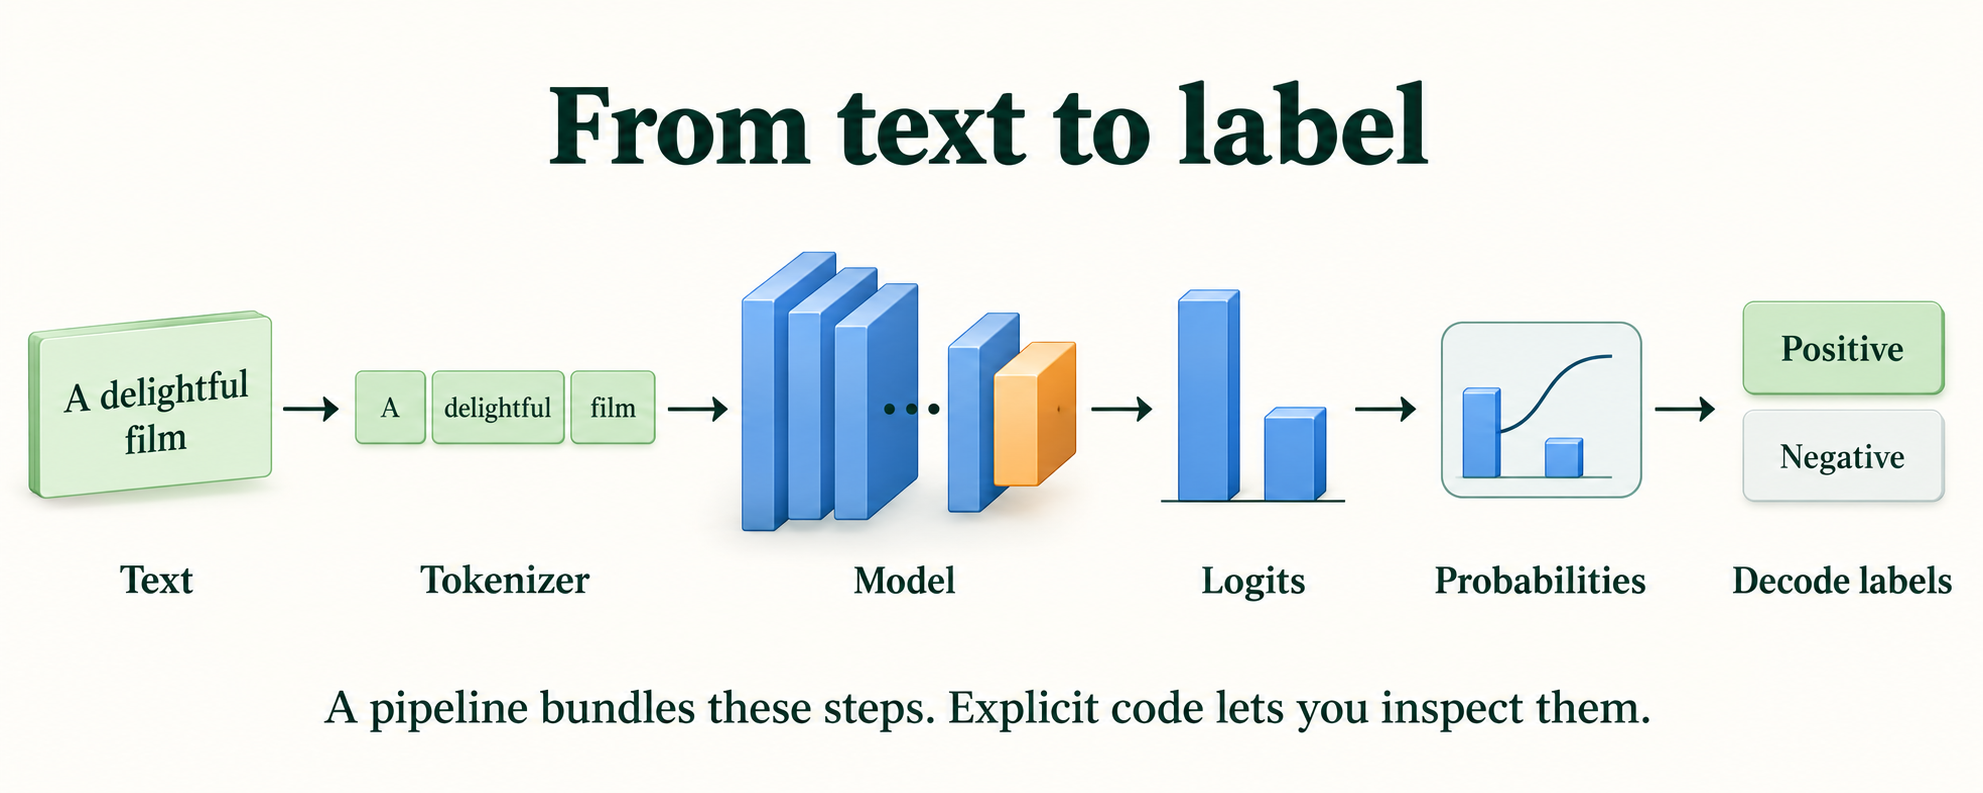

*Figure 7.4.1. Tokenization, model computation, logits, probabilities and label mapping are separate steps. Weights stay fixed during this inference flow.*

We'll use the fixed IMDb split from Note 7.1 (its function is copied here so the notebook stands alone; the fingerprints confirm the reviews are the same) and work with the first 32 validation reviews.

In [2]:
def load_imdb_split(seed=0, n_val=2500, n_eval=1000, verbose=True):
    """The fixed IMDb split shared by every note in Modules 7 and 8 (built in Note 7.1)."""
    ds = load_dataset("stanfordnlp/imdb", cache_dir="data/imdb",
                      data_files={"train": "plain_text/train-*.parquet",
                                  "test":  "plain_text/test-*.parquet"}, revision=DATASET_REVISIONS.get("stanfordnlp/imdb"))
    def dedup(texts, labels, seen):
        keep = []
        for i, t in enumerate(texts):
            if t not in seen:                              # keep only the first copy of each review
                seen.add(t); keep.append(i)
        return [texts[i] for i in keep], np.array([labels[i] for i in keep])
    tr_x, tr_y = dedup(list(ds["train"]["text"]), list(ds["train"]["label"]), set())
    te_x, te_y = dedup(list(ds["test"]["text"]), list(ds["test"]["label"]), set(tr_x))  # also drops test reviews already in train
    if verbose:
        print(f"official split: {len(ds['train'])} train, {len(ds['test'])} test reviews")
        print(f"duplicates removed: {len(ds['train']) - len(tr_x)} from train, "
              f"{len(ds['test']) - len(te_x)} from test (repeats, or reviews that are also in train)")
    clean = lambda xs: [x.replace("<br />", " ") for x in xs]                         # remove HTML line breaks
    rng = np.random.default_rng(seed)
    p = rng.permutation(len(tr_x)); v, t = p[:n_val], p[n_val:]                       # validation is carved from train
    q = rng.permutation(len(te_x))[:n_eval]                                           # a fixed sample of the test set
    split = {"train": (clean([tr_x[i] for i in t]), tr_y[t]),
             "val":   (clean([tr_x[i] for i in v]), tr_y[v]),
             "test":  (clean(te_x), te_y)}
    split["val_eval"] = (split["val"][0][:n_eval], split["val"][1][:n_eval])
    split["test_eval"] = (clean([te_x[i] for i in q]), te_y[q])
    return split

def fingerprint(texts):
    """A short ID for a set of texts: identical sets give identical fingerprints."""
    return hashlib.sha256("\n".join(sorted(texts)).encode()).hexdigest()[:12]

In [3]:
imdb = load_imdb_split()
for name, (x, y) in imdb.items():
    print(f"{name:<9} {len(x):>6} reviews | positive share {y.mean():.3f} | fingerprint {fingerprint(x)}")
reviews, labels = imdb["val_eval"][0][:32], imdb["val_eval"][1][:32]     # the first 32 validation reviews

official split: 25000 train, 25000 test reviews
duplicates removed: 96 from train, 322 from test (repeats, or reviews that are also in train)
train      22404 reviews | positive share 0.502 | fingerprint fb3a1229f951
val         2500 reviews | positive share 0.492 | fingerprint 07758bc36c9b
test       24678 reviews | positive share 0.503 | fingerprint 429c5557b6d4
val_eval    1000 reviews | positive share 0.495 | fingerprint 9934ffeaac91
test_eval   1000 reviews | positive share 0.515 | fingerprint fc9fa98701bc


## 2. The Pipeline API

A **pipeline** bundles a tokeniser, a model and the decoding step for one task. We create one by naming the task and the model. Always pass `device`. If you don't, the library picks a device itself, and on some machines (for example a Mac with an Apple GPU) it will choose the GPU even though the rest of your code runs on the CPU. Your results could then differ slightly from someone else's for no obvious reason.

In [4]:
SST2 = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
clf = pipeline("text-classification", model=SST2, device=device, revision=MODEL_REVISIONS.get(SST2))        # always say which device
print("device:", clf.device)
print("tokenizer:", type(clf.tokenizer).__name__, "| model:", type(clf.model).__name__)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 9881.02it/s]

device: cpu
tokenizer: BertTokenizer | model: DistilBertForSequenceClassification


Inside are the two objects we'll load ourselves in Section 3: a `BertTokenizer` (Note 7.2 explained why a DistilBERT model gets a BERT tokeniser) and a `DistilBertForSequenceClassification` model.

By default, a text-classification pipeline returns only the best label and its probability. `top_k=None` returns every class:

In [5]:
print(clf("A slow start, but the final act is unforgettable."))
print(clf("A slow start, but the final act is unforgettable.", top_k=None))   # every class, not just the best

[{'label': 'POSITIVE', 'score': 0.9997346997261047}]
[{'label': 'POSITIVE', 'score': 0.9997346997261047}, {'label': 'NEGATIVE', 'score': 0.0002653122355695814}]


The model is sure this mixed sentence is positive: 0.9997346997261047 for POSITIVE and 0.0002653122355695814 for NEGATIVE, which add up to 1.

Give a pipeline a list and it returns a list. For real reviews you should always set the truncation length, and for many texts a `batch_size`, so they are processed several at a time (Section 6 measures why).

In [6]:
pipe_out = clf(reviews, truncation=True, max_length=256, batch_size=8)   # a list in, a list of results out
pipe_pos = np.array([o["score"] if o["label"] == "POSITIVE" else 1 - o["score"] for o in pipe_out])
print(f"{len(pipe_out)} results | first three: {pipe_out[:3]}")
print(f"accuracy on these 32 reviews: {((pipe_pos > 0.5) == labels).mean():.3f}")

32 results | first three: [{'label': 'NEGATIVE', 'score': 0.9940033555030823}, {'label': 'POSITIVE', 'score': 0.9994484782218933}, {'label': 'POSITIVE', 'score': 0.9966138005256653}]
accuracy on these 32 reviews: 0.906


The first review comes out NEGATIVE with probability 0.9940033555030823, and the model gets 0.906 of these 32 reviews right. We keep each review's probability of POSITIVE (for a NEGATIVE result, that is 1 minus the score) to compare against our own code in the next section.

> **Key terms**
> - **Pipeline:** a Hugging Face object that bundles a tokeniser, a model and output decoding for one task.
> - **`top_k`:** how many of the highest-scoring labels a classification pipeline returns; `None` means all of them.
> - **`batch_size`:** how many inputs are processed together in one forward pass.

> **Common mistake:** creating a pipeline without `device=`. The library's automatic choice can differ between machines, so the same notebook can run on different hardware for different people, with slightly different numbers. State the device explicitly.

## 3. Loading Tokenizers and Models Explicitly

The explicit route uses the two Auto classes from Note 7.2. For a classification model we use `AutoModelForSequenceClassification`, which builds the body *and* the classification head. Two more steps follow loading: `.to(device)` moves the weights to the chosen device, and `.eval()` switches the model to inference behaviour (Section 5 shows why).

In [7]:
tokenizer = AutoTokenizer.from_pretrained(SST2, revision=MODEL_REVISIONS.get(SST2))
model = AutoModelForSequenceClassification.from_pretrained(SST2, revision=MODEL_REVISIONS.get(SST2))
model = model.to(device).eval()                         # move to the device; switch off dropout (Section 5)
print(type(tokenizer).__name__, "|", type(model).__name__, "|", model.config.id2label)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 13784.41it/s]

BertTokenizer | DistilBertForSequenceClassification | {0: 'NEGATIVE', 1: 'POSITIVE'}


The configuration's `id2label` tells us that output 0 means NEGATIVE and output 1 means POSITIVE. We need it to decode the outputs.

Now we process the same 32 reviews ourselves, in batches of 8, and compare the probabilities with the pipeline's. Each step is one line: tokenise with truncation and padding, run the model, and apply softmax to the logits.

In [8]:
probs = []
with torch.inference_mode():
    for i in range(0, len(reviews), 8):                                         # batches of 8
        enc = tokenizer(reviews[i:i + 8], truncation=True, max_length=256,
                        padding=True, return_tensors="pt").to(device)          # (8, longest in batch)
        probs.append(model(**enc).logits.softmax(dim=-1)[:, 1].cpu())          # (8,) probability of POSITIVE
explicit_pos = torch.cat(probs).numpy()
print("largest difference from the pipeline's probabilities:", f"{np.abs(explicit_pos - pipe_pos).max():.2e}")
print("same labels for all 32 reviews:", bool(((explicit_pos > 0.5) == (pipe_pos > 0.5)).all()))

largest difference from the pipeline's probabilities: 5.96e-08
same labels for all 32 reviews: True


The largest difference between our probabilities and the pipeline's is 5.96e-08, a rounding-level difference in the last digits of 32-bit arithmetic, and all 32 labels agree. Our explicit code does exactly what the pipeline does. The rest of this note looks at each of its steps in turn.

> **Key terms**
> - **`AutoModelForSequenceClassification`:** the Auto class that builds a model with a whole-text classification head.
> - **`id2label`:** the configuration's map from output position to label name.

**Check yourself.**

1. Our explicit code and the pipeline agree to within 5.96e-08. Name two settings that, if you changed them in only one of the two, would make them disagree by much more.

<details>
<summary>Worked answer</summary>

For example: a different `max_length` (the model would see different amounts of each long review), leaving out the attention mask in one of them (padded reviews would change), running one in train mode (dropout would add noise), or pairing the model with a different tokeniser. Any of these changes the model's input or behaviour, not just the arithmetic.

</details>

## 4. Preprocessing and Decoding Outputs

### 4.1 Padding and attention masks

A model processes a batch as one tensor, and a tensor must be a rectangle: every row the same length. Texts are not. **Padding** fixes this by adding a filler token to the end of each shorter text until all match the longest. Let's tokenise two texts of different lengths.

In [9]:
pair = ["A great film.", "Not my kind of film at all, sadly."]
enc = tokenizer(pair, padding=True, return_tensors="pt")
print("keys:", list(enc.keys()))
print("input_ids:\n", enc["input_ids"])
print("attention_mask:\n", enc["attention_mask"])
print("tokens of the shorter text:", tokenizer.convert_ids_to_tokens(enc["input_ids"][0]))
print("padding token:", tokenizer.pad_token, "= ID", tokenizer.pad_token_id, "| added on the", tokenizer.padding_side)

keys: ['input_ids', 'token_type_ids', 'attention_mask']
input_ids:
 tensor([[  101,  1037,  2307,  2143,  1012,   102,     0,     0,     0,     0,
             0,     0],
        [  101,  2025,  2026,  2785,  1997,  2143,  2012,  2035,  1010, 13718,
          1012,   102]])
attention_mask:
 tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])
tokens of the shorter text: ['[CLS]', 'a', 'great', 'film', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
padding token: [PAD] = ID 0 | added on the right


The tokeniser returns three tensors. Look at `input_ids`: both rows start with 101 (`[CLS]`) and the real text ends with 102 (`[SEP]`), as in Note 7.2. The first text needs only 6 tokens, so it is padded with six zeros: the padding token `[PAD]` has ID 0, added on the right. (`token_type_ids` is the extra BERT output from Note 7.2, which DistilBERT ignores.)

The **attention mask** has a 1 for every real token and a 0 for every padding position. The model uses it inside attention: positions with a 0 are blocked, so no real token can attend to padding. It is the same idea as the causal mask in Note 6.3, which blocked future positions. Without it, the meaningless `[PAD]` vectors would be mixed into the real tokens' representations.

### 4.2 Truncation

The opposite problem is a text that is too long. DistilBERT can read at most 512 tokens, because it has only 512 learned position embeddings (Note 7.1, Section 6). **Truncation** cuts a text down to a maximum length. Here is the longest of the 1,000 `val_eval` reviews, tokenised with and without it:

In [10]:
long_review = max(imdb["val_eval"][0], key=len)                     # the longest of the 1,000 val_eval reviews
full = tokenizer(long_review)["input_ids"]
cut = tokenizer(long_review, truncation=True, max_length=256)["input_ids"]
print(f"tokens without truncation: {len(full)} | with max_length=256: {len(cut)} | model limit: {tokenizer.model_max_length}")
print("the truncated version still ends with:", tokenizer.convert_ids_to_tokens(cut[-3:]))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1602 > 512). Running this sequence through the model will result in indexing errors


tokens without truncation: 1602 | with max_length=256: 256 | model limit: 512
the truncated version still ends with: ['first', 'off', '[SEP]']


Without truncation, the review is 1602 tokens long, and the tokeniser prints a warning that this is longer than the model's limit of 512. With `max_length=256` it becomes exactly 256 tokens, and it still ends with a proper `[SEP]` token: truncation cuts off the end of the *text*, but keeps the special tokens. Everything after the cut is simply never seen by the model.

What happens if we ignore the warning and pass the full review to the model?

In [11]:
try:
    with torch.inference_mode():
        model(input_ids=torch.tensor([full]).to(device))           # too long for the model
except Exception as e:
    print(type(e).__name__, "|", str(e).splitlines()[0][:150])

RuntimeError | The size of tensor a (1602) must match the size of tensor b (512) at non-singleton dimension 1


The model fails: a `RuntimeError` complaining that a tensor of size 1602 doesn't match one of size 512, the position-embedding table. (With some library versions, the error is an `IndexError` instead.) That warning from the tokeniser was worth reading. Always set `truncation=True` and a `max_length` for real-world text.

### 4.3 Why the attention mask matters

Padding should change nothing about a review's prediction: a review should get the same answer whether it is processed alone or in a batch next to a longer one. Let's test that on our 32 reviews. We process them as one padded batch, once *with* the attention mask and once *without* it, and compare each against processing the review alone, where it needs no padding at all.

In [12]:
batch = tokenizer(reviews, truncation=True, max_length=256, padding=True, return_tensors="pt").to(device)
print("batch shape:", tuple(batch["input_ids"].shape), "| padding share:",
      f"{1 - batch['attention_mask'].float().mean().item():.1%}")
with torch.inference_mode():
    with_mask = model(**batch).logits.softmax(-1)[:, 1].cpu().numpy()
    no_mask = model(input_ids=batch["input_ids"]).logits.softmax(-1)[:, 1].cpu().numpy()   # mask left out
    alone = np.array([model(**tokenizer(r, truncation=True, max_length=256, return_tensors="pt").to(device))
                      .logits.softmax(-1)[0, 1].item() for r in reviews])              # one review at a time
padded = (batch["attention_mask"] == 0).any(dim=1).cpu().numpy()     # reviews that received padding
print(f"reviews with padding: {padded.sum()} of {len(reviews)}")
print(f"with mask vs. one at a time: largest difference {np.abs(with_mask - alone).max():.2e}")
print(f"no mask   vs. one at a time: largest difference {np.abs(no_mask - alone).max():.3f} | "
      f"labels changed: {((no_mask > 0.5) != (alone > 0.5)).sum()}")

batch shape: (32, 256) | padding share: 18.4%


reviews with padding: 15 of 32
with mask vs. one at a time: largest difference 2.21e-06
no mask   vs. one at a time: largest difference 0.764 | labels changed: 2


In this batch, 15 of the 32 reviews needed padding, and 18.4% of all positions are padding. With the mask, every review's probability matches the one-at-a-time result to within 2.21e-06, rounding noise. Without the mask, probabilities move by as much as 0.764, and 2 reviews flip to the wrong side of 0.5. Same model, same reviews; the only difference is whether the model was told which positions were real. Passing the whole tokeniser output with `model(**enc)` includes the mask automatically. The danger is code that passes only `input_ids`.

### 4.4 From logits to probabilities to labels

The model's raw output is a pair of **logits**, unnormalised scores, one per class. To turn them into probabilities we apply **softmax**, as in Module 2: exponentiate each logit, then divide by the sum so they add up to 1. Here it is by hand for the first review:

In [13]:
review = reviews[0]
enc = tokenizer(review, truncation=True, max_length=256, return_tensors="pt").to(device)
with torch.inference_mode():
    logits = model(**enc).logits[0].cpu()                          # (2,) raw scores, one per class
exp = logits.exp()
probs_by_hand = exp / exp.sum()                                    # softmax: exponentiate, then normalise
label = model.config.id2label[int(probs_by_hand.argmax())]
print("logits:", [round(v, 3) for v in logits.tolist()])
print("exp(logits):", [round(v, 4) for v in exp.tolist()], "| sum:", round(exp.sum().item(), 4))
print("probabilities:", [round(v, 4) for v in probs_by_hand.tolist()], "->", label)
print("pipeline said:", pipe_out[0], "| true label:", model.config.id2label[int(labels[0])])

logits: [2.772, -2.338]
exp(logits): [15.9923, 0.0965] | sum: 16.0887
probabilities: [0.994, 0.006] -> NEGATIVE
pipeline said: {'label': 'NEGATIVE', 'score': 0.9940033555030823} | true label: NEGATIVE


The logits are 2.772 for NEGATIVE and −2.338 for POSITIVE. Exponentiating gives 15.9923 and 0.0965, which sum to 16.0887. Dividing each by the sum gives probabilities 0.994 and 0.006. The larger one wins, and `id2label` turns position 0 into the word NEGATIVE. That's exactly the pipeline's answer (NEGATIVE, 0.9940033555030823), and it matches the true label.

Two practical points. First, only the *difference* between logits matters: adding the same number to both leaves the softmax unchanged. Second, a probability of 0.994 is the model's confidence, not a guarantee. Note 7.1 showed this model confidently wrong about an idiom, and Note 7.5 looks at how far to trust these scores.

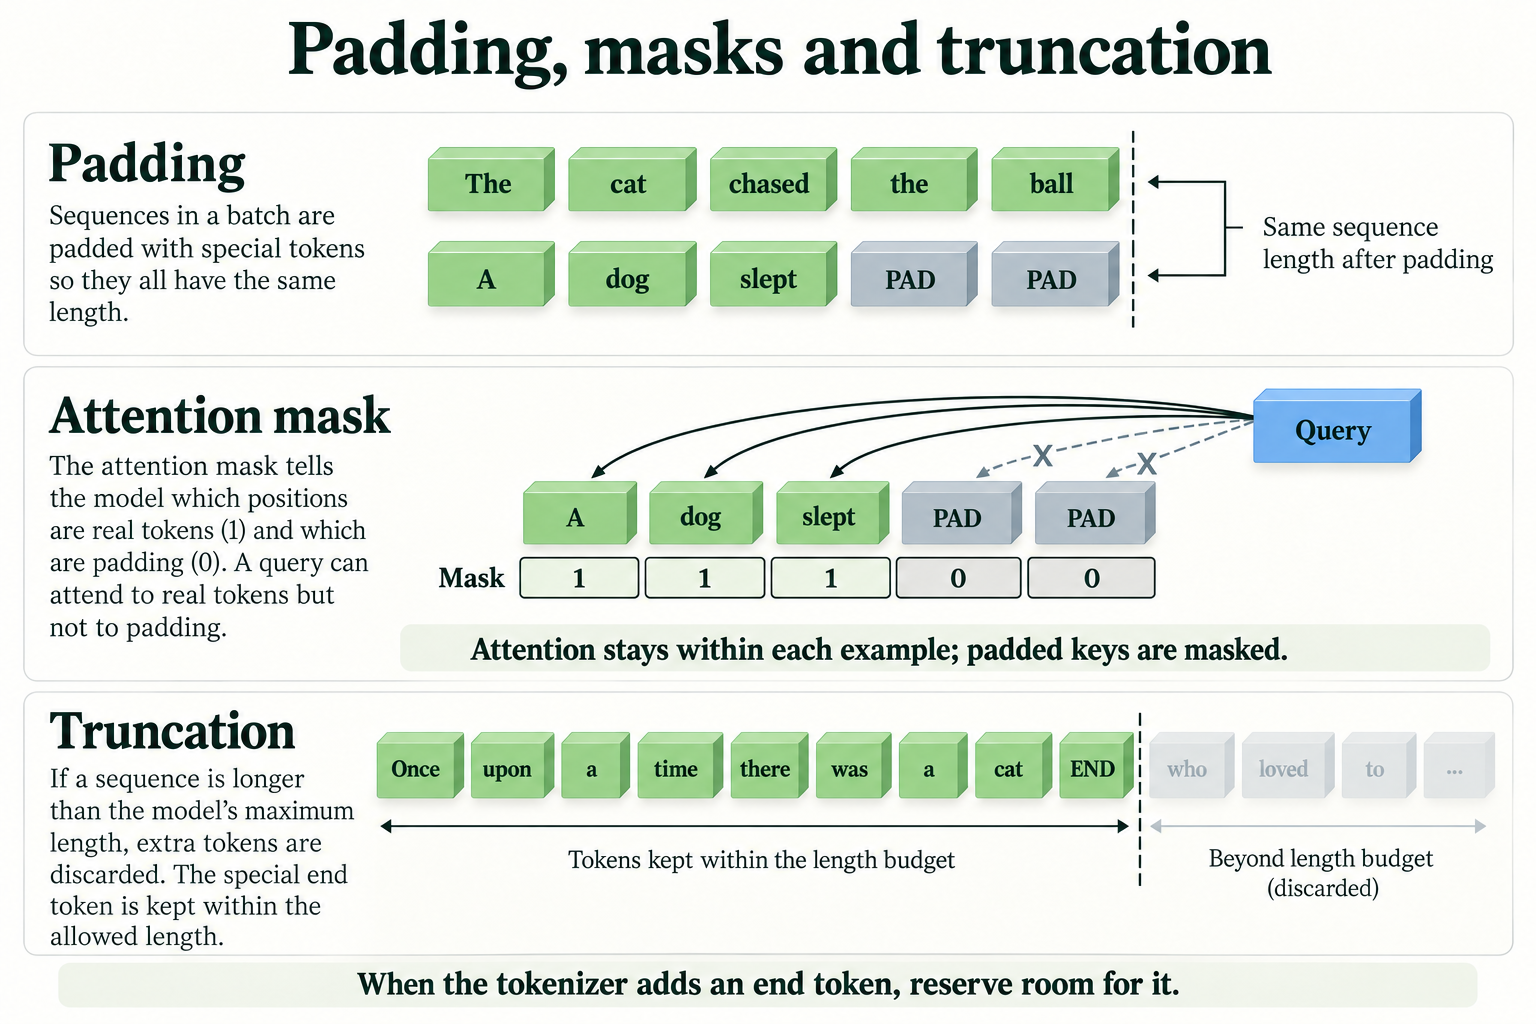

*Figure 7.4.2. Padding adds positions, an attention mask restricts access to padded positions, and truncation discards input. This illustration is not a causal future-token mask.*

> **Key terms**
> - **Padding:** adding filler tokens (`[PAD]`, ID 0 here) so all texts in a batch have the same length.
> - **Attention mask:** a tensor of 1s (real tokens) and 0s (padding) that stops attention from using padding positions.
> - **Truncation:** cutting a text down to a maximum number of tokens; `truncation=True, max_length=…`.
> - **Logits:** a model's raw, unnormalised output scores, one per class.
> - **Softmax:** the function that turns logits into probabilities: exponentiate, then divide by the sum.

> **Common mistake:** calling the model with `input_ids` only, for example `model(enc["input_ids"])`, on a padded batch. Nothing fails, but padded reviews get different, wrong predictions. Pass the whole encoding with `model(**enc)` so the attention mask goes in too.

**Check yourself.**

1. A batch has two reviews, of 40 and 300 tokens, and you tokenise with `truncation=True, max_length=256, padding=True`. What is the shape of `input_ids`, and how many 0s are in the first row of the attention mask?

<details>
<summary>Worked answer</summary>

The longer review is cut to 256 tokens, so the batch is padded to 256: `input_ids` has shape `(2, 256)`. The first review has 40 real tokens (including `[CLS]` and `[SEP]`), so its mask row has 40 ones and 256 − 40 = 216 zeros.

</details>

**Check yourself.**

1. Logits of `[2.772, −2.338]` give probabilities `[0.994, 0.006]`. What probabilities would logits of `[12.772, 7.662]` give, and why?

<details>
<summary>Worked answer</summary>

The same, `[0.994, 0.006]`. Both logits were increased by 10, and softmax depends only on the differences between logits: adding 10 multiplies every exponential by the same factor, which cancels when dividing by the sum. The difference is 5.11 in both cases.

</details>

**Visual walkthrough: Follow padding and attention masking.**

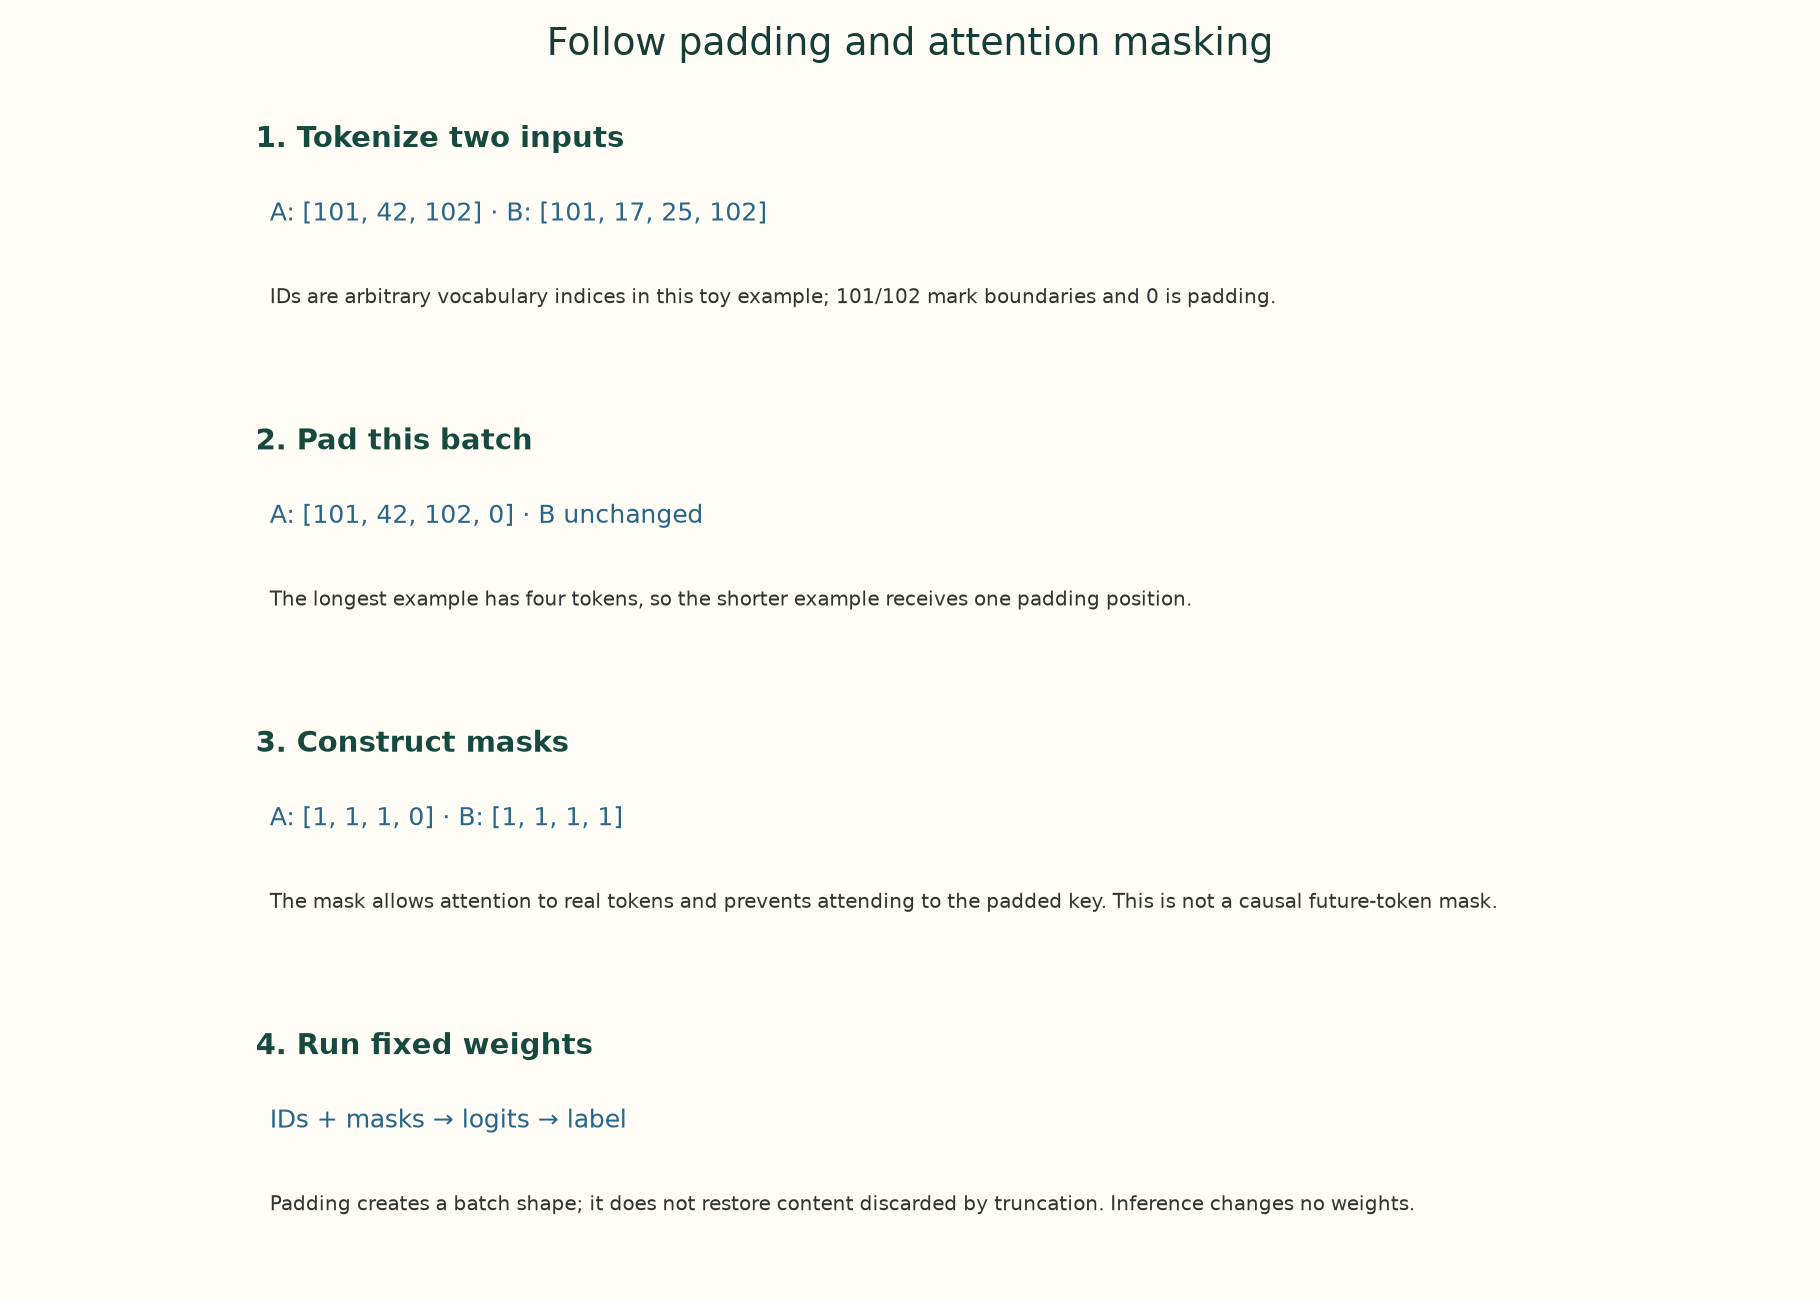

**1. Tokenize two inputs.** A: [101, 42, 102] · B: [101, 17, 25, 102]. IDs are arbitrary vocabulary indices in this toy example; 101/102 mark boundaries and 0 is padding.

**2. Pad this batch.** A: [101, 42, 102, 0] · B unchanged. The longest example has four tokens, so the shorter example receives one padding position.

**3. Construct masks.** A: [1, 1, 1, 0] · B: [1, 1, 1, 1]. The mask allows attention to real tokens and prevents attending to the padded key. This is not a causal future-token mask.

**4. Run fixed weights.** IDs + masks → logits → label. Padding creates a batch shape; it does not restore content discarded by truncation. Inference changes no weights.

*The app adds a paused animation of this same supplied example.*

## 5. Running Inference: Eval Mode, Inference Mode, Device Placement

### 5.1 Eval mode

In Module 3 you met **dropout**, which randomly switches off a share of the network's units during training to reduce overfitting. That randomness is useful while learning but harmful when you want a stable answer. PyTorch models have two modes: `model.train()` turns dropout on and `model.eval()` turns it off. `from_pretrained` already returns a model in eval mode, but it is good practice to call `.eval()` explicitly, because any code that calls `.train()` (for example a fine-tuning loop in Module 8) switches dropout back on.

Here is the same review, run three times in each mode:

In [14]:
enc = tokenizer(reviews[0], truncation=True, max_length=256, return_tensors="pt").to(device)
model.train()                                                       # dropout ON (training behaviour)
with torch.inference_mode():
    train_runs = [model(**enc).logits[0, 1].item() for _ in range(3)]
model.eval()                                                        # dropout OFF (inference behaviour)
with torch.inference_mode():
    eval_runs = [model(**enc).logits[0, 1].item() for _ in range(3)]
print("train mode, same input 3 times:", [round(v, 4) for v in train_runs])
print("eval mode,  same input 3 times:", [round(v, 4) for v in eval_runs])

train mode, same input 3 times: [-2.3716, -2.78, -2.0684]
eval mode,  same input 3 times: [-2.3384, -2.3384, -2.3384]


In train mode, the POSITIVE logit for one and the same review comes out as -2.3716, -2.78 and -2.0684: dropout makes every run different. In eval mode it is -2.3384 every time. A model left in train mode gives answers that change on every call, and slightly worse ones on average.

### 5.2 Inference mode

During training, PyTorch records every operation so that it can compute gradients later (Module 2's autograd). At inference time there is nothing to learn, and that recording only wastes memory and time. Two context managers switch it off:

In [15]:
out_plain = model(**enc)
with torch.no_grad():
    out_nograd = model(**enc)
with torch.inference_mode():
    out_inf = model(**enc)
print("plain call:      requires_grad =", out_plain.logits.requires_grad, "| grad_fn =", type(out_plain.logits.grad_fn).__name__)
print("torch.no_grad:   requires_grad =", out_nograd.logits.requires_grad)
print("inference_mode:  requires_grad =", out_inf.logits.requires_grad, "| inference tensor:", out_inf.logits.is_inference())

plain call:      requires_grad = True | grad_fn = AddmmBackward0
torch.no_grad:   requires_grad = False
inference_mode:  requires_grad = False | inference tensor: True


A plain call produces logits that require gradients and carry a `grad_fn` (here `AddmmBackward0`), the record PyTorch keeps for backpropagation, along with every intermediate tensor it needs. Under `torch.no_grad()` nothing is recorded. `torch.inference_mode()` goes slightly further: its outputs are marked as **inference tensors**, which lets PyTorch skip some extra bookkeeping. For pure prediction, `inference_mode` is the best choice. Use `no_grad` if you need to use the outputs later in code that records gradients.

### 5.3 Device placement

A model's weights and its inputs must be on the same device. If the model is on a GPU and the inputs are on the CPU, PyTorch stops with an error saying they are on different devices. The pattern is always the same: move the model once with `model.to(device)`, and move every batch with `enc.to(device)`, as all our cells have done.

In [16]:
print("model is on:", next(model.parameters()).device, "| inputs are on:", enc["input_ids"].device)

model is on: cpu | inputs are on: cpu


In this notebook both are on the CPU. On a machine with an NVIDIA GPU, the setup cell would choose `cuda`, and the same code would place both on the GPU. Note 7.6 compares the two.

> **Key terms**
> - **Eval mode / train mode:** `model.eval()` disables dropout (and other training-only behaviour); `model.train()` enables it.
> - **`torch.no_grad()` / `torch.inference_mode()`:** context managers that stop PyTorch recording operations for gradients; `inference_mode` is the faster, stricter one.
> - **Device placement:** putting the model's weights and its input tensors on the same device (CPU or GPU).

> **Common mistake:** forgetting `.eval()` after training or fine-tuning. The model keeps dropout on, so evaluation scores are noisy and slightly too low, and the same input gives different answers each time.

**Check yourself.**

1. A colleague's evaluation script gives a slightly different accuracy every time it runs on the same data with the same model. Name the most likely cause, and how you would check for it.

<details>
<summary>Worked answer</summary>

The model is probably in train mode, so dropout makes every run slightly different. Check with `model.training` (it should be `False`), or run the same input twice and compare the outputs. If they differ, call `model.eval()` before evaluating.

</details>

## 6. Batching Inputs and Managing Memory

### 6.1 Padding waste

Batching lets the model process several texts in one forward pass, which uses the hardware more efficiently. But a padded batch is as long as its longest member, so every shorter review pays for tokens it doesn't have. How much waste depends on which reviews end up together. Here are the first 256 validation reviews in batches of 32, in the order given and sorted by length.

In [17]:
texts = imdb["val_eval"][0][:256]                                       # the first 256 validation reviews
lengths = np.array([len(ids) for ids in tokenizer(texts, truncation=True, max_length=256)["input_ids"]])
def padded_tokens(order, batch_size=32):
    return sum(lengths[order[i:i + batch_size]].max() * len(order[i:i + batch_size])
               for i in range(0, len(order), batch_size))               # every review padded to its batch's longest
as_given, by_length = np.arange(len(texts)), np.argsort(lengths)
print(f"real tokens: {lengths.sum():,}")
for name, order in [("in the given order", as_given), ("sorted by length", by_length)]:
    total = padded_tokens(order)
    print(f"batches of 32, {name:<18}: {total:,} tokens processed | padding {1 - lengths.sum() / total:.1%}")

real tokens: 50,878
batches of 32, in the given order: 65,536 tokens processed | padding 22.4%
batches of 32, sorted by length  : 53,984 tokens processed | padding 5.8%


The 256 reviews contain 50,878 real tokens. Batched in the order given, the model processes 65,536 positions, so 22.4% of its work is spent on padding. Sorted by length, similar lengths share a batch, and the total drops to 53,984, with only 5.8% padding. Same reviews, same model, a fifth less work. (Every batch in the given order was padded to the full 256 tokens, because each batch of 32 happened to contain at least one long review.) If you sort, remember to put the results back in the original order afterwards.

### 6.2 Timing batch sizes

Let's time it. We run the 256 reviews with batch sizes 1, 8 and 32, then batch size 32 sorted by length. The timings are printed with units; yours will differ, since they depend on your processor.

In [18]:
def time_per_review(order, batch_size):
    with torch.inference_mode():
        t0 = benchmark_clock()
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            enc = tokenizer([texts[j] for j in idx], truncation=True, max_length=256,
                            padding=True, return_tensors="pt").to(device)
            model(**enc)
        return (benchmark_clock() - t0) / len(order)

time_per_review(as_given[:32], 32)                                       # warm-up, not reported
for name, order, bs in [("batch size 1", as_given, 1), ("batch size 8", as_given, 8),
                        ("batch size 32", as_given, 32), ("batch size 32, sorted", by_length, 32)]:
    print(f"{name:<22} {time_per_review(order, bs) * 1000:6.2f} ms per review")

batch size 1            22.65 ms per review


batch size 8            21.47 ms per review


batch size 32           19.55 ms per review


batch size 32, sorted   16.22 ms per review


On this CPU, larger batches are somewhat faster per review than one review at a time, and sorting by length gives a further saving on top, roughly in line with the padding it removes. The gain from batching on a CPU is modest. A GPU can process many more inputs in parallel, so there the gain from batching is usually much larger (Note 7.6).

### 6.3 Memory

Batching has a cost: memory. While a batch passes through the model, every layer holds the vectors of every token, and attention computes a score for every pair of tokens in every head. We can estimate both for DistilBERT from its configuration (768 numbers per token, 12 heads, 4 bytes per number):

In [19]:
cfg = model.config
print("numbers per token:", cfg.dim, "| attention heads:", cfg.n_heads)
for B, L in [(1, 256), (32, 256), (32, 512), (256, 512)]:
    hidden = B * L * cfg.dim * 4                                           # one layer's token vectors, float32
    scores = B * cfg.n_heads * L * L * 4                                   # one layer's attention scores
    print(f"batch {B:>3} x {L} tokens: token vectors {hidden / 1e6:7.1f} MB | attention scores {scores / 1e6:7.1f} MB (per layer)")

numbers per token: 768 | attention heads: 12
batch   1 x 256 tokens: token vectors     0.8 MB | attention scores     3.1 MB (per layer)
batch  32 x 256 tokens: token vectors    25.2 MB | attention scores   100.7 MB (per layer)
batch  32 x 512 tokens: token vectors    50.3 MB | attention scores   402.7 MB (per layer)
batch 256 x 512 tokens: token vectors   402.7 MB | attention scores  3221.2 MB (per layer)


One review of 256 tokens needs about 0.8 MB of token vectors per layer, and 3.1 MB if the attention scores are stored in full. A batch of 32 multiplies both by 32 (25.2 MB and 100.7 MB). Doubling the length to 512 doubles the token vectors but *quadruples* the attention scores, to 402.7 MB, because scores grow with length squared (Note 6.3). A batch of 256 reviews at 512 tokens would need 3221.2 MB just for one layer's scores. Libraries often avoid storing the full score matrix, but the lesson holds: memory grows with batch size × length, and faster still with length when attention is computed in full. If a large batch runs out of memory, reduce the batch size or the maximum length.

> **Key terms**
> - **Batching:** processing several inputs in one forward pass.
> - **Padding waste:** computation spent on padding positions in a batch.
> - **Sorting by length (length bucketing):** grouping inputs of similar length into the same batch to reduce padding.

**Check yourself.**

1. You need to classify one million short product reviews overnight on a CPU. Describe two changes from Section 6 that would make it faster, and one thing you must be careful about if you sort the reviews.

<details>
<summary>Worked answer</summary>

Batch the reviews (for example 32 at a time) instead of processing them one by one, and sort them by length so each batch has little padding. Truncating to a sensible `max_length` also helps. If you sort, you must keep track of each review's original position and put the predictions back in the original order; otherwise predictions get attached to the wrong reviews.

</details>

## 7. Saving and Reloading Models and Tokenizers

An application that downloads its model from the Hub every time it starts depends on the Hub being available, and on the model not having changed (Note 7.1, Section 7). Often you want your own copy. `save_pretrained` writes a model or tokeniser to a folder in the same format as a Hub repository, and `from_pretrained` accepts a folder path as well as a repository name. In Module 8 this is how you'll save your fine-tuned models.

In [20]:
save_dir = "data/sst2-copy"
model.save_pretrained(save_dir)
tokenizer.save_pretrained(save_dir)
for f in sorted(os.listdir(save_dir)):
    print(f"{f:<26} {os.path.getsize(os.path.join(save_dir, f)) / 1e6:9.3f} MB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 19.08it/s]

config.json                    0.001 MB
model.safetensors            267.833 MB
tokenizer.json                 0.712 MB
tokenizer_config.json          0.000 MB


The folder holds the configuration, the weights (267.833 MB, the same size as on the Hub) and the tokeniser. The library saved it as one `tokenizer.json` file, the Tokenizers library's complete description of the tokeniser, rather than the `vocab.txt` file the Hub repository had. "Writing model shards" refers to the weights file: very large models are split into several files, called **shards**. This one fits in one.

Now let's reload from the folder and check that nothing changed:

In [21]:
tok2 = AutoTokenizer.from_pretrained(save_dir, revision=MODEL_REVISIONS.get(save_dir))                             # loads from a folder, not the Hub
model2 = AutoModelForSequenceClassification.from_pretrained(save_dir, revision=MODEL_REVISIONS.get(save_dir)).to(device).eval()
enc = tokenizer(reviews[:8], truncation=True, max_length=256, padding=True, return_tensors="pt").to(device)
enc2 = tok2(reviews[:8], truncation=True, max_length=256, padding=True, return_tensors="pt").to(device)
with torch.inference_mode():
    same = torch.equal(model(**enc).logits, model2(**enc2).logits)
print("same token IDs:", torch.equal(enc["input_ids"], enc2["input_ids"]), "| identical outputs:", same)
shutil.rmtree(save_dir)                                                    # tidy up: this copy is 268 MB
print("deleted", save_dir)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 6992.08it/s]

same token IDs: True | identical outputs: True
deleted data/sst2-copy


The reloaded tokeniser produces the same token IDs, and the reloaded model produces outputs identical to the original, bit for bit. We then delete the copy, because it takes as much disk as the original model. In a real project you would keep it, and record which repository and commit it came from.

> **Key terms**
> - **`save_pretrained`:** saves a model or tokeniser to a folder in Hub format.
> - **`from_pretrained(path)`:** loads from a local folder as well as from a Hub repository name.
> - **Shard:** one of several files that together hold a large model's weights.

> **Common mistake:** saving the model but not the tokeniser. The folder then can't be used on its own, and someone may pair the model with a different tokeniser. Save both into the same folder.

**Check yourself.**

1. You fine-tune a model, save it with `model.save_pretrained("my-model")`, and send the folder to a colleague. Their `AutoTokenizer.from_pretrained("my-model")` fails. What did you forget, and why does it matter which tokeniser they use?

<details>
<summary>Worked answer</summary>

You saved the model but not the tokeniser: also run `tokenizer.save_pretrained("my-model")`. It matters because the model only understands token IDs from its own tokeniser. If your colleague loads a tokeniser from somewhere else, the IDs may mean different tokens (or come from a different vocabulary), and the model's predictions would be wrong, possibly without any error.

</details>

## Putting It All Together

Let's reassemble the whole path from repository to prediction.

A **pipeline** does five steps for you, and you can do each yourself. **Load** the tokeniser and model from the same repository, with `AutoTokenizer` and `AutoModelForSequenceClassification`, moving the model to a device and into eval mode. Our explicit code matched the pipeline to within 5.96e-08 on 32 reviews. **Preprocess** with truncation (a review of 1602 tokens crashed the model until it was cut to fit), padding (so a batch is a rectangle) and the attention mask (without it, padded reviews' probabilities moved by up to 0.764 and 2 labels flipped). **Run** in eval mode (train mode gave three different answers for one review) and under `inference_mode` (no gradient recording), with model and inputs on the same device. **Decode** logits with softmax: [2.772, −2.338] became [0.994, 0.006], and `id2label` turned position 0 into NEGATIVE. **Batch** sensibly: sorting by length cut padding from 22.4% to 5.8% of the work, and memory grows with batch × length, faster with length when attention scores are stored in full. **Save** with `save_pretrained` and reload with `from_pretrained(folder)`, which gave identical outputs.

| Step | The call | What goes wrong without it |
|---|---|---|
| Load as a pair | `AutoTokenizer` + `AutoModel…` from one repository | IDs mean the wrong tokens (Note 7.2) |
| Device | `pipeline(..., device=device)`, `model.to(device)`, `enc.to(device)` | different hardware per machine, or a device error |
| Truncate | `truncation=True, max_length=256` | a crash on long inputs (1602 > 512) |
| Mask | `model(**enc)` | wrong predictions for padded inputs (2 of 32 flipped) |
| Eval mode | `model.eval()` | a different answer every run |
| No gradients | `torch.inference_mode()` | wasted memory and time |
| Decode | `softmax` + `id2label` | raw scores that aren't probabilities |
| Save | `save_pretrained` for model *and* tokeniser | a folder that can't be used on its own |

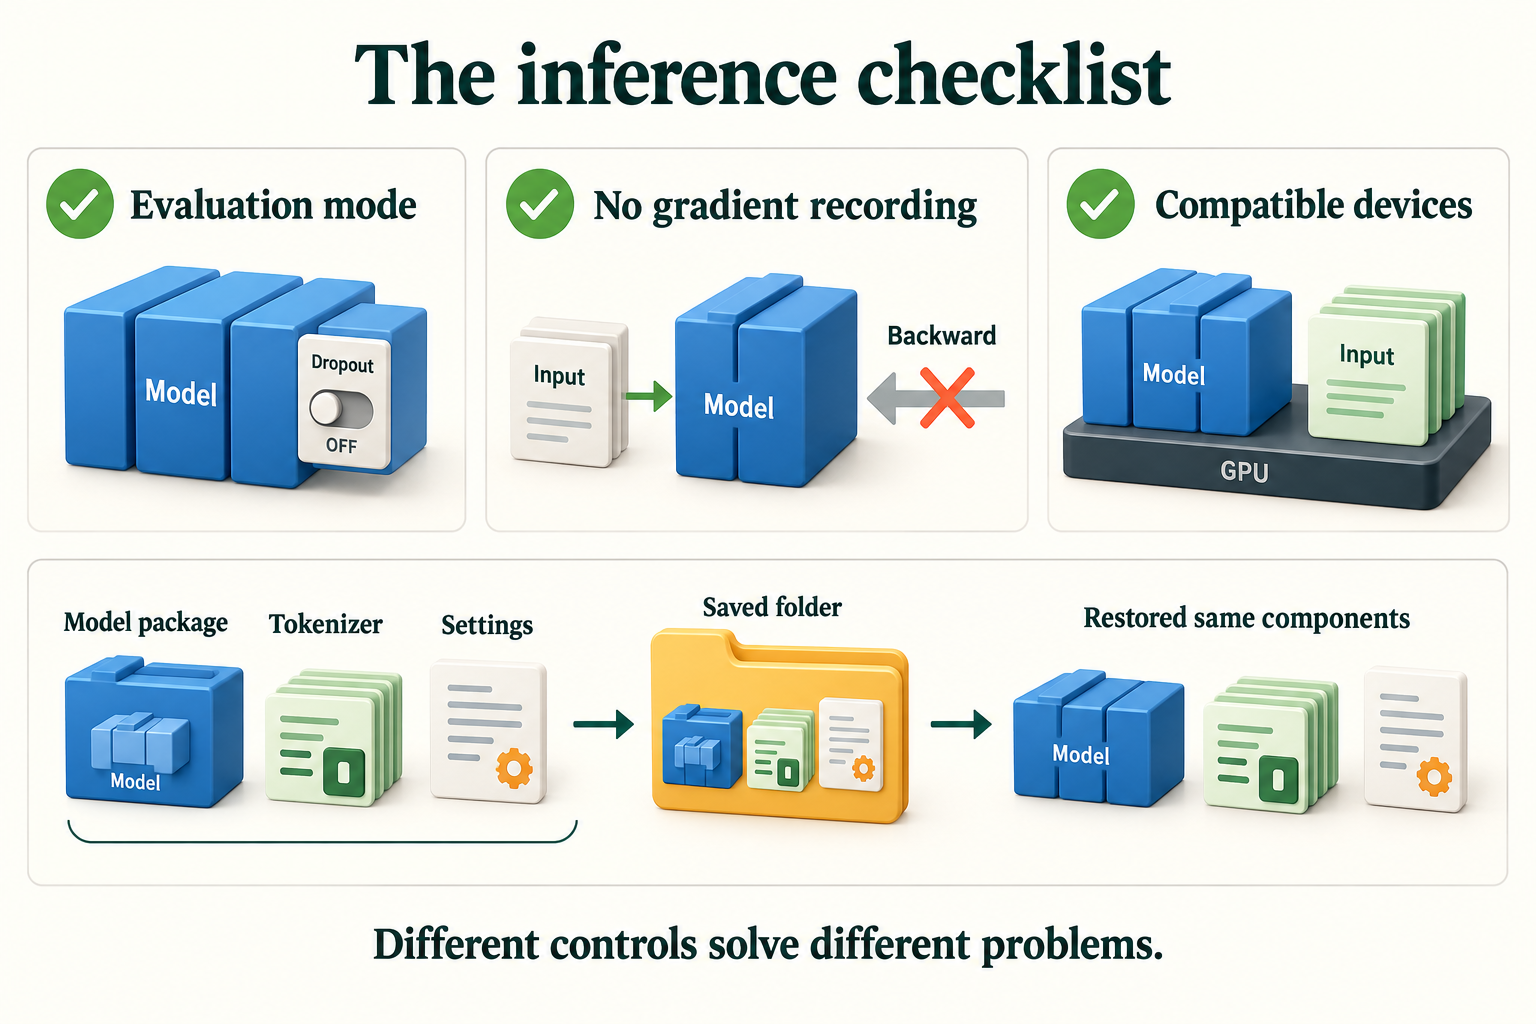

*Figure 7.4.3. Evaluation mode controls layers such as dropout; no-gradient inference controls autograd. Model and inputs must use compatible devices. Save preprocessing and settings too.*

## Summary

- A pipeline bundles tokeniser, model and decoding; always pass `device=` explicitly, and use `truncation`, `max_length` and `batch_size` for real data. `top_k=None` returns every class's probability.
- The explicit route, `AutoTokenizer` plus `AutoModelForSequenceClassification`, `.to(device)` and `.eval()`, reproduced the pipeline's probabilities to within 5.96e-08.
- **Padding** makes batches rectangular (`[PAD]`, ID 0, on the right); the **attention mask** marks real tokens with 1 and padding with 0. Leaving the mask out moved probabilities by up to 0.764 and flipped 2 of 32 labels.
- **Truncation** keeps inputs within the model's limit: a 1602-token review crashed DistilBERT, whose limit is 512.
- **Softmax** turns logits into probabilities: [2.772, −2.338] → [0.994, 0.006] → NEGATIVE via `id2label`.
- **Eval mode** turns off dropout (train mode gave a different logit on each of three runs); **`inference_mode`** stops gradient recording.
- **Sorting by length** reduced padding from 22.4% to 5.8% of the processed positions; memory grows with batch × length, and with length squared for full attention scores.
- **`save_pretrained`** and **`from_pretrained(folder)`** save and reload a model and tokeniser with identical outputs. Always save both.

## Glossary

| Term | Meaning |
|---|---|
| Pipeline | An object bundling a tokeniser, a model and output decoding for one task. |
| `top_k` | How many top labels a classification pipeline returns; `None` returns all. |
| Batch size | How many inputs are processed together in one forward pass. |
| `AutoModelForSequenceClassification` | The Auto class for a model with a whole-text classification head. |
| `id2label` | The configuration's map from output position to label name. |
| Padding | Filler tokens added so all texts in a batch have equal length. |
| Attention mask | 1s for real tokens and 0s for padding, so attention ignores padding. |
| Truncation | Cutting a text down to a maximum number of tokens. |
| `max_length` | The maximum number of tokens kept when truncating. |
| Logits | A model's raw, unnormalised output scores. |
| Softmax | Exponentiate each logit, then divide by the sum, giving probabilities. |
| Dropout | A training technique that randomly switches off units; disabled in eval mode. |
| Eval mode / train mode | Model states that disable / enable training-only behaviour such as dropout. |
| `torch.inference_mode()` | A context manager that disables gradient recording for faster inference. |
| Inference tensor | A tensor created under `inference_mode`, excluded from gradient tracking. |
| Device placement | Putting model weights and inputs on the same device. |
| Padding waste | Computation spent on padding positions. |
| Length bucketing | Grouping inputs of similar length into batches to reduce padding. |
| `save_pretrained` | Saves a model or tokeniser to a folder in Hub format. |
| Shard | One of several files holding a large model's weights. |